# CNN Training Using a Custom Dataset



## Rememorize

In [1]:
!pip install -q "pillow>=8.0,<13.0"
!pip install -q -U gdown

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

`from torchvision import transforms` provides tools to **resize**, **crop**, **rotate**, **normalize**, **convert**, and **augment** images before feeding them into a neural network.

The original images might have:
- Different dimensions (e.g., 128 × 128, 256 × 256).
- Different pixel formats.
- Different brightness and contrast.
- Pixel values ranging from 0 to 255.

However, neural network generally expects images in a consistent tensor format and shape.

`torchvision.transforms` helps prepare the images.

**Common Transformation**  

| Transformation | Purpose |
|----------------|---------|
| `Resize()` | Resize images to a specified dimension |
| `CenterCrop()` | Crop the center portion of an image |
| `RandomCrop()`	| Randomly crop an image |
| `RandomHorizontalFlip()` | Randomly flip images horizontally |
| `RandomRotation()` | Randomly rotate images |
| `ToTensor()` | Convert an image into a PyTorch tensor |
| `Normalize()` | Normalize image pixel values |
| `ColorJitter()` | Randomly adjust brightness, contrast, saturation, and hue |

In [3]:
# Download file from Google Drive
# Download dataset file
# !gdown "https://drive.google.com/file/d/1FZO4ojM03tP1lTaiVHShzDX5oMDTi3oZ/view?usp=sharing"

# Download model
!gdown "https://drive.google.com/file/d/1TVLnsCWw5Jn2fGzVsjF5eP_A9DkLGFOV/view?usp=sharing"
# !gdown "https://drive.google.com/file/d/1R3skOdRxd4cH87kCr8FWpp5Z83_nramq/view?usp=sharing"
# !gdown "https://drive.google.com/file/d/1KRTbdnuWckUVI0NaNUlaFc4jjVYJUUax/view?usp=drive_link"

Downloading...
From (original): https://drive.google.com/uc?id=1TVLnsCWw5Jn2fGzVsjF5eP_A9DkLGFOV
From (redirected): https://drive.google.com/uc?id=1TVLnsCWw5Jn2fGzVsjF5eP_A9DkLGFOV&confirm=t&uuid=d29bd74e-f63c-495d-9c43-bb21c0abd4cc
To: /content/cnn_model.pth
100% 35.4M/35.4M [00:00<00:00, 35.4MB/s]


In [4]:
# Unzip the zipped file
!unzip "/content/Classification_dataset_v3.zip"

Archive:  /content/Classification_dataset_v3.zip
   creating: Classification_dataset_v3/
  inflating: Classification_dataset_v3/Dataset_info.txt  
   creating: Classification_dataset_v3/images/
   creating: Classification_dataset_v3/images/test/
   creating: Classification_dataset_v3/images/test/Cat/
  inflating: Classification_dataset_v3/images/test/Cat/cat_1000.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1001.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1002.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1003.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1004.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1005.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1006.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1007.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1008.jpg  
  inflating: Classification_dataset_v3/images/test/Cat/cat_1009.jpg 

In [5]:
train_dir = '/content/Classification_dataset_v3/images/train'
for label, class_ in enumerate(os.listdir(train_dir)):
    print(label, class_)

0 Dog
1 Cat
2 Person


In [6]:
class ImageDataset(Dataset):
    def __init__(self, img_dir, transform=None):
        self.image_dir = img_dir     # directory of specific images directory
        self.image_paths = []        # collection of image paths
        self.labels = []             # images labelling
        self.class_name = {}         # matching between labels and class_
        self.transform = transform   # image transformation method

        # Get all paths of each class (Dog, Cat, Person)
        for label, class_ in enumerate(os.listdir(self.image_dir)):
            self.class_name[label] = class_
            class_path = os.path.join(self.image_dir, class_)

            # Append all directories of images and related class labels from "train" folder
            for img_name in os.listdir(class_path):
                self.image_paths.append(os.path.join(class_path, img_name))
                self.labels.append(label)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]
        image = Image.open(image_path).convert('RGB')
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label

In [7]:
# Define a sequence of image transformations using transforms.Compose()
transform = transforms.Compose([

                    # Resize the input image to 128 × 128 pixels
                    # Ensures all images have the same dimensions
                    transforms.Resize((128, 128)),

                    # Convert the image into a PyTorch tensor
                    transforms.ToTensor(),

                    # Normalize the RGB image using the specified mean and standard deviation
                    # Applies the formula: (pixel_value - mean) / standard_deviation
                    # For each RGB channel, mean = 0.5 and std = 0.5
                    # Converts pixel values from [0.0, 1.0] to approximately [-1.0, 1.0]
                    transforms.Normalize(mean = [0.5, 0.5, 0.5],
                                         std = [0.5, 0.5, 0.5])
                    ])

In [8]:
transform = transforms.Compose([
    transforms.Resize((128,128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])]
)
# mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]

In [9]:
train_image_dir = '/content/Classification_dataset_v3/images/train'
test_image_dir = '/content/Classification_dataset_v3/images/test'

train_image_dataset = ImageDataset(img_dir=train_image_dir, transform=transform)
test_image_dataset = ImageDataset(img_dir=test_image_dir, transform=transform)

In [10]:
train_image_loader = DataLoader(dataset=train_image_dataset, batch_size=32, shuffle=True)
test_image_loader = DataLoader(dataset=test_image_dataset, batch_size=32, shuffle=True)

In [11]:
# Print out for first five 32 batches of images
for _, (img, label) in enumerate(train_image_loader):
    if _ < 5:
        print(f"{_+1}. Image shape: {img.shape} | Label shape: {label.shape}")
    else: break

1. Image shape: torch.Size([32, 3, 128, 128]) | Label shape: torch.Size([32])
2. Image shape: torch.Size([32, 3, 128, 128]) | Label shape: torch.Size([32])
3. Image shape: torch.Size([32, 3, 128, 128]) | Label shape: torch.Size([32])
4. Image shape: torch.Size([32, 3, 128, 128]) | Label shape: torch.Size([32])
5. Image shape: torch.Size([32, 3, 128, 128]) | Label shape: torch.Size([32])


This represents a 4-dimensional tensor containing 32 images.
| Dimension | Value	| Meaning |
|-----------|-------|---------|
|0	| 32 | Number of images in the batch |
|1	| 3 | Number of color channels (RGB) |
|2	| 128 | Image height |
|3	| 128 | Image width |

In [12]:
# Check "class_name" of each loaded dataset
print(train_image_dataset.class_name)
print(test_image_dataset.class_name)

{0: 'Dog', 1: 'Cat', 2: 'Person'}
{0: 'Dog', 1: 'Cat', 2: 'Person'}


torch.Size([32, 3, 128, 128]) torch.Size([32])
(3, 128, 128)
Dog
(128, 128, 3)


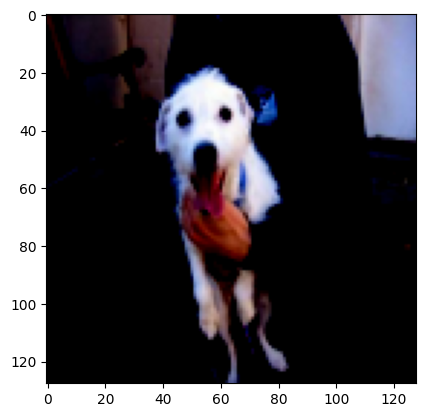

In [13]:
# Iterate through the training DataLoader one batch at a time
for images, labels in train_image_loader:

    # Display: images = [32, 3, 128, 128], labels = [32]
    print(images.shape, labels.shape)

    # Retrieve the first image from the batch
    img = images[0].numpy() # convert PyTorch tensor into Numpy array

    # Display image: (3, 128, 128) → Channels, Height, Width
    print(img.shape)

    # Retrieve the label of the first image
    label = labels[0].item() # .item() converts a single-element tensor into a Python integer

    # Convert the numerical label into its corresponding class name
    print(train_image_dataset.class_name[label]) # 0 → Cat, 1 → Person, 2 → Dog

    # Rearrange dimensions → (Channels, Height, Width) to (Height, Width, Channels)
    # Matplotlib expects the image format (H, W, C) for RGB images
    img = np.transpose(img, (1, 2, 0))

    # Display the new image shape
    print(img.shape) # (128, 128, 3)

    # Display the image using Matplotlib
    # vmin and vmax define the displayed intensity range
    plt.imshow(img, vmin=0, vmax=255)

    # Stop after processing the first batch
    break

# Custom CNN Architecture

In [14]:
import torch.nn as nn
import torch.optim as optim

### Create model

$\displaystyle \boxed{\text{ Conv } | \text{ BN } | \text{ ReLU } | \text{ MP }} \to \boxed{\text{ Conv } | \text{ BN } | \text{ ReLU } | \text{ MP }} \to \boxed{\text{ Conv } | \text{ BN } | \text{ ReLU } | \text{ MP }} \to \boxed{\text{ Conv } | \text{ BN } | \text{ ReLU } | \text{ MP }}$

In [4]:
class CustomCNNModel(nn.Module):

    def __init__(self, input_dim, num_classes):
        super(CustomCNNModel, self).__init__()
        self.input_dim = input_dim
        self.num_classes = num_classes

        # Create a Sequential container for the CNN convolutional layers
        # PURPOSE: Feature extraction
        self.conv_layers = nn.Sequential(

            # ==================== C1: First Convolution Block ====================
            # Apply 32 convolutional filters to the input RGB image
            nn.Conv2d(
                in_channels=3,   # Input has 3 channels (RGB)
                out_channels=32, # Generate 32 feature maps
                kernel_size=3,   # Each filter has a spatial size of 3 × 3
                stride=1,        # Move the filter 1 pixel at a time
                padding=1        # Add 1 pixel of padding around the image to preserve its spatial dimensions
            ),

            # Normalize the 32 output feature maps using Batch Normalization
            # Helps stabilize and improve the training process
            nn.BatchNorm2d(32),

            # Apply the ReLU activation function
            nn.ReLU(),

            # Apply Max Pooling with a 2 × 2 window
            # Reduces the height and width by half
            # stride=2: Move the pooling window 2 pixels at a time
            nn.MaxPool2d(kernel_size=2, stride=2),


            # ==================== C2: Second Convolution Block ====================
            # Apply 64 convolutional filters to the 32 input feature maps
            nn.Conv2d(
                in_channels=32,  # Input has 32 channels
                out_channels=64, # Generate 64 feature maps
                kernel_size=3,   # Each filter has a spatial size of 3 × 3
                stride=1,        # Move the filter 1 pixel at a time
                padding=1        # Add 1 pixel of padding around the image to preserve its spatial dimensions
            ),

            # Normalize the 64 output feature maps
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),


            # ==================== C3: Third Convolution Block ====================
            # Apply 128 convolutional filters to the 64 input feature maps
            nn.Conv2d(
                in_channels=64,   # Input has 64 channels
                out_channels=128, # Generate 128 feature maps
                kernel_size=3,    # Each filter has a spatial size of 3 × 3
                stride=1,         # Move the filter 1 pixel at a time
                padding=1         # Add 1 pixel of padding around the image to preserve its spatial dimensions
            ),

            # Normalize the 128 output feature maps
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),


            # ==================== C4: Fourth Convolution Block ====================
            # Apply 256 convolutional filters to the 128 input feature maps
            nn.Conv2d(
                in_channels=128,   # Input has 128 channels
                out_channels=256,  # Generate 256 feature maps
                kernel_size=3,     # Each filter has a spatial size of 3 × 3
                stride=1,          # Move the filter 1 pixel at a time
                padding=1          # Add 1 pixel of padding around the image to preserve its spatial dimensions
            ),

            # Normalize the 256 output feature maps
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self._to_linear = None
        self._get_conv_output(self.input_dim)

        # PURPOSE: Classification
        self.fc_layers = nn.Sequential(
            nn.Linear(self._to_linear, 512),
            nn.ReLU(),
            # nn.Dropout(0.2)
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, self.num_classes),
        )

    # Calculate the number of features produced by the CVN layers after processing an input image.
    def _get_conv_output(self, input_dim=128):
        # Disable gradient calculations because this is only a shape calculation
        with torch.no_grad():

            # Create a dummy input tensor
            dummy_input = torch.zeros(1, 3, input_dim, input_dim)
            # NOTE: shape: (batch size, channels, width, height)

            # Pass the dummy input through all convolutional layers
            output = self.conv_layers(dummy_input)

            # Flatten the convolutional output and calculate its total features
            self._to_linear = output.view(1, -1).size(1)

    def forward(self, x):

        # Pass input images through convolutional layers
        x = self.conv_layers(x)

        # Flatten the convolutional output into a 2D tensor
        x = x.view(x.size(0), -1)

        # Pass flattened features through fully connected layers
        x = self.fc_layers(x)

        # Return the predicted class scores (logits)
        return x

When we create a python class, it follows this sequence:
1. It creates the class object and registers its methods, including `_get_conv_output()`.
2. It creates an instance of CustomCnnModel.
3. It executes `__init__()`.
4. Inside `__init__()`, `self._get_conv_output()` looks up the already-defined method on the class and calls it.
The important distinction: Python executes the class definition first, then executes `__init__()` when you instantiate the class.

Therefore, the order of method definitions inside a class does not matter. What matters is that the method exists when you call it.


**Model Architecture**  

![image.png](./data/)

In [16]:
# Initialize model

# Check GPU will be used if available, else use CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

# Move model's parameters and buffers to the appropriate device
model = CustomCNNModel(input_dim=128, num_classes=3).to(device)

cuda


> `.to(device)` method moves the model's parameters and buffers to the selected device.

In [17]:
print(model)

CustomCNNModel(
  (conv_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.

In [18]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(params=model.parameters(), lr=0.001)

> You don't need to add **Softmax** inside the model when using `nn.CrossEntropyLoss()`, because that loss function internally handles the necessary log-softmax calculation.

In [19]:
len(train_image_loader)

95

### Train and save model

In [20]:
# Define the total number of training epochs
# One epoch means the model has processed the entire training dataset once.
epochs = 40

# Start the training process and repeat for 40 epochs
for epoch in range(epochs):

    # Set the model to training mode.
    model.train()

    # Initialize the cumulative training loss for the current epoch
    running_loss = 0.0

    # Iterate through the training DataLoader batch by batch.
    # Each batch contains images and their corresponding labels.
    for images, labels in train_image_loader:
        # Move both input images and labels to the selected device (GPU or CPU).
        # Images shape: [32, 3, 128, 128]
        # Labels shape: [32]
        images, labels = images.to(device), labels.to(device)

        # Clear gradients from the previous training iteration.
        optimizer.zero_grad()

        # Forward propagation:
        # Pass the input images through the CNN model to obtain class scores (logits).
        # Outputs shape: [32, 3]
        outputs = model(images)

        # Calculate the loss by comparing predicted logits with the actual labels.
        # Measures how far the model's predictions are from the correct classes.
        loss = criterion(outputs, labels)

        # Backpropagation:
        # Calculate gradients of the loss with respect to the model's trainable parameters.
        loss.backward()

        # Update model parameters using the calculated gradients.
        # The optimizer adjusts weights and biases to reduce the loss.
        optimizer.step()

        # Add the current batch loss to the cumulative loss for this epoch.
        # .item() converts the scalar loss tensor into a Python number.
        running_loss += loss.item()

    # Calculate and display the average batch loss for the current epoch.
    # epoch + 1 displays epoch numbering starting from 1 instead of 0.
    print(f"Epoch: {epoch+1}/{epochs} | Loss: {running_loss / len(train_image_loader):.4f}")

Epoch: 1/40 | Loss: 0.9716
Epoch: 2/40 | Loss: 0.5994
Epoch: 3/40 | Loss: 0.5337
Epoch: 4/40 | Loss: 0.4885
Epoch: 5/40 | Loss: 0.4300
Epoch: 6/40 | Loss: 0.3785
Epoch: 7/40 | Loss: 0.3818
Epoch: 8/40 | Loss: 0.3279
Epoch: 9/40 | Loss: 0.2779
Epoch: 10/40 | Loss: 0.2631
Epoch: 11/40 | Loss: 0.1988
Epoch: 12/40 | Loss: 0.1816
Epoch: 13/40 | Loss: 0.1336
Epoch: 14/40 | Loss: 0.1602
Epoch: 15/40 | Loss: 0.1279
Epoch: 16/40 | Loss: 0.1094
Epoch: 17/40 | Loss: 0.0793
Epoch: 18/40 | Loss: 0.0649
Epoch: 19/40 | Loss: 0.0506
Epoch: 20/40 | Loss: 0.0539
Epoch: 21/40 | Loss: 0.0648
Epoch: 22/40 | Loss: 0.0247
Epoch: 23/40 | Loss: 0.0152
Epoch: 24/40 | Loss: 0.0507
Epoch: 25/40 | Loss: 0.0335
Epoch: 26/40 | Loss: 0.0599
Epoch: 27/40 | Loss: 0.0190
Epoch: 28/40 | Loss: 0.0153
Epoch: 29/40 | Loss: 0.0209
Epoch: 30/40 | Loss: 0.0143
Epoch: 31/40 | Loss: 0.0438
Epoch: 32/40 | Loss: 0.0488
Epoch: 33/40 | Loss: 0.0482
Epoch: 34/40 | Loss: 0.0107
Epoch: 35/40 | Loss: 0.0286
Epoch: 36/40 | Loss: 0.0267
E

In [21]:
# Saves model with learned parameters (weights and biases)
torch.save(model.state_dict(), "cnn_model.pth")

### Load and evaluate model

In [5]:
# Load CustomCNNModel
model_path = "/content/cnn_model.pth"
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = CustomCNNModel(input_dim=128, num_classes=3).to(device)
model.load_state_dict(torch.load(model_path, map_location=device))

<All keys matched successfully>

In [6]:
print(model)

CustomCNNModel(
  (conv_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.

In [7]:
for images, labels in test_image_loader:
  print(images.shape, labels.size())
  break

NameError: name 'test_image_loader' is not defined

In [32]:
# Evaluate model on the test dataset
model.eval()  # Set the model to evaluation mode

correct = 0  # Initialize the counter for correctly predicted samples
total = 0    # Initialize the counter for the total number of evaluated samples

# Disable gradient calculation because we are only evaluating the model, not training it
with torch.no_grad():

    # Iterate through the test dataset one batch at a time
    for images, labels in test_image_loader:

        # Move the input images and their corresponding labels to the selected device (CPU or GPU)
        images, labels = images.to(device), labels.to(device)

        # Pass the images through the model to obtain the predicted class scores (logits)
        outputs = model(images)

        # Get the class index with the highest score for each image
        # torch.max(outputs, 1) returns two tensors:
        #   - Maximum values (highest scores)
        #   - Indices of those maximum values (predicted class labels)
        _, predicted = torch.max(outputs, 1)
        # print(f"Predicted label: {predicted}")
        # print(f"Actual label: {labels}")
        # print(f"Total matched labels: {(predicted == labels).sum()}")

        # Add the number of labels in the current batch to the total sample count
        total += labels.size(0)

        # Compare predicted labels with actual labels
        # (predicted == labels) returns a Boolean tensor (True for correct predictions)
        # .sum() counts the number of correct predictions
        # .item() converts the resulting single-value tensor into a Python number
        correct += (predicted == labels).sum().item()

# Calculate and display the test accuracy as a percentage
# Accuracy = (Number of Correct Predictions / Total Number of Samples) * 100
print(f"Test accuracy is: {100 * correct / total:.2f}%")

Test accuracy is: 21.00%


### Image classification

In [11]:
import cv2

In [14]:
# Define a class for loading the trained TorchScript model and performing image classification
class ImageClassifier:

    # Initialize the classifier with the saved model path and class names
    def __init__(self, model_path, class_names):

        # Check whether a CUDA-enabled GPU is available; otherwise, use the CPU
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

        # Load the saved TorchScript model and map it to the selected device
        self.model = CustomCNNModel(input_dim=128, num_classes=3).to(device)
        self.model.load_state_dict(torch.load(model_path, map_location=device))

        # Switch the model to evaluation mode
        self.model.eval()

        # Store the class names used during model training
        self.class_names = class_names

        # Define the image preprocessing transformations
        # These transformations should match the preprocessing used during model training
        self.transform = transforms.Compose([

            # Resize the input image to 128 × 128 pixels
            transforms.Resize((128, 128)),

            # Convert the PIL image into a PyTorch tensor
            # Changes the image format from (H × W × C) to (C × H × W)
            # Converts pixel values from [0, 255] to [0, 1]
            transforms.ToTensor(),

            # Normalize the RGB channels using the specified mean and standard deviation
            # Converts pixel values from approximately [0, 1] to [-1, 1]
            transforms.Normalize(mean=[0.5, 0.5, 0.5],
                                 std=[0.5, 0.5, 0.5])
            ])

    # Define a method to classify an input image
    def predict(self, image_path):

        # Open the image using PIL and convert it to RGB (3 color channels)
        image = Image.open(image_path).convert('RGB')

        # Apply the preprocessing transformations to the image
        # unsqueeze(0) adds a batch dimension: [3, 128, 128] → [1, 3, 128, 128]
        # Move the input tensor to the same device as the model
        input_tensor = self.transform(image).unsqueeze(0).to(self.device)

        # Disable gradient calculations because this is inference, not model training
        with torch.no_grad():

            # Pass the preprocessed image through the trained model
            # Output shape: [1, 3] because there is one image and three classes
            output = self.model(input_tensor)

            # Find the class with the highest prediction score
            # torch.max(output, 1) returns:
            #   - Maximum prediction scores
            #   - Indices of the maximum scores (predicted class indices)
            # The underscore (_) ignores the maximum scores
            _, predicted = torch.max(output, 1)

            # Convert the predicted class index into a Python integer
            label = self.class_names[predicted.item()]

        # Read the original image using OpenCV
        # OpenCV loads images in BGR color format
        img = cv2.imread(image_path)

        # Draw the predicted class name on the original image
        cv2.putText(img=img,                           # Original image on which the text will be drawn
                    text=label,                        # Predicted class name
                    org=(10, 30),                      # Position of the text (x=10, y=30)
                    fontFace=cv2.FONT_HERSHEY_COMPLEX, # Font style
                    fontScale=1,                       # Font size multiplier
                    color=(0, 0, 255),                 # Text color in BGR format (red)
                    thickness=2)                       # Thickness of the text


        # Save the image with the predicted class name in its filename
        cv2.imwrite(f"Photo_of_{label}.jpg", img)

        # Convert the image from BGR to RGB format for Matplotlib
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Display the image with the predicted class name
        plt.imshow(img)

        # Hide the x-axis and y-axis
        plt.axis('off')

        # Return the predicted class name
        return label

{0: 'Dog', 1: 'Cat', 2: 'Person'}
Enter your image path:/content/Cat.jpg


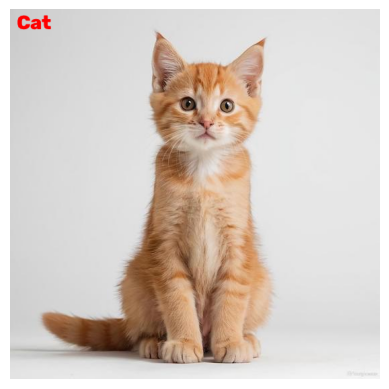

In [18]:
class_names = {0: 'Dog', 1: 'Cat', 2: 'Person'}
# class_names = test_image_dataset.class_name
print(class_names)
classfier = ImageClassifier(model_path, class_names)
image_path = input("Enter your image path:")
label = classfier.predict(image_path)

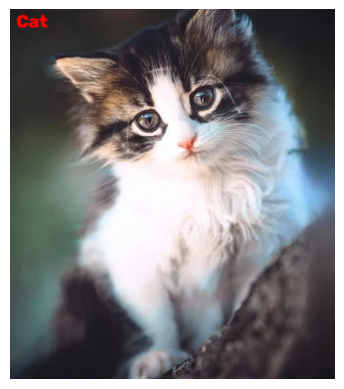

In [ ]:
/content/Cat.jpgimg_path = "/content/shopping.webp"
label = classfier.predict(img_path)